In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

In [2]:
BATCH_SIZE = 32
IMAGE_SIZE = 640
CHANNELS = 3

In [4]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    r'/home/smartcity_sp7/praveen/save_3_classes_data',
    shuffle=True,
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

Found 954 files belonging to 3 classes.


In [5]:
class_names = dataset.class_names
class_names

['AK', 'BCC', 'SK']

In [6]:
def flatten_dataset(dataset):
    flat_data = []
    target_data = []
    for image_batch, labels_batch in dataset:
        for img, label in zip(image_batch, labels_batch):
            img_array = img.numpy().astype('uint8')
            img_flattened = img_array.flatten()
            flat_data.append(img_flattened)
            target_data.append(label.numpy())
    return np.array(flat_data), np.array(target_data)

In [20]:
train_size = int(0.85 * len(dataset))
test_size = int(0.15 * len(dataset))

In [21]:
train_ds = dataset.take(train_size)
test_ds = dataset.skip(train_size).take(test_size)

In [22]:
x_train, y_train = flatten_dataset(train_ds)
x_test, y_test = flatten_dataset(test_ds)

In [23]:
# Creating a support vector classifier
svc=SVC(probability=True, random_state=72)

In [24]:
from sklearn import svm

svc = svm.SVC(max_iter=5000) 

In [25]:
svc.fit(x_train,y_train)

SVC(C=1.0, break_ties=False, cache_size=200, class_weight=None, coef0=0.0,
    decision_function_shape='ovr', degree=3, gamma='scale', kernel='rbf',
    max_iter=5000, probability=False, random_state=None, shrinking=True,
    tol=0.001, verbose=False)

In [26]:
y_pred = svc.predict(x_test)

In [27]:
accuracy = accuracy_score(y_test, y_pred)
print("The model is {:.2f}% accurate".format(accuracy * 100))

The model is 72.66% accurate


In [28]:
from sklearn.metrics import classification_report

print("Validation metrics for Normal Random Forest:")
print(classification_report(y_true=y_test, y_pred=y_pred, target_names=class_names))

Validation metrics for Normal Random Forest:
              precision    recall  f1-score   support

          AK       0.67      0.65      0.66        31
         BCC       0.78      0.65      0.70        48
          SK       0.72      0.86      0.79        49

    accuracy                           0.73       128
   macro avg       0.72      0.72      0.72       128
weighted avg       0.73      0.73      0.72       128



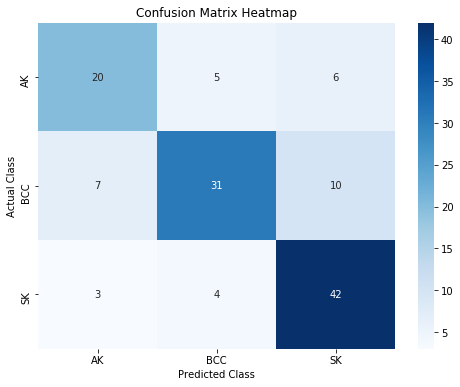

In [29]:
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, columns=class_names, index=class_names)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix Heatmap")
plt.show()